# Morphology class performance heatmap: plotting (R half)

This is **part 2 of 2** (R kernel). It reads the per-(split, patient, treatment+dose, model) accuracy summary written by **`2a.plot_morphology_class_heatmap.ipynb`** (Python kernel) and renders it as a single heatmap with **ComplexHeatmap**:

- **a 2x2 grid of panels, one per data split**: `[train | val]` on top, `[test | holdout]` on the bottom. Split isn't a 1:1 property of patient or treatment — most patients have samples in every split (only the two holdout patients are exclusively "holdout") — so it can't be a single color bar on one panel; each split needs its own panel. `ComplexHeatmap`'s `+`/`%v%` heatmap-list concatenation can only produce an all-horizontal or all-vertical list (not a true 2D grid), so each panel is drawn independently into its own cell of a `grid.layout(2, 3)` (2x2 for the panels, +1 column for a single shared legend) — the pattern the ComplexHeatmap docs recommend for combining several heatmaps into one multi-panel figure.
- **within each panel: rows = patient, columns = drug + dose** (e.g. `Trametinib (10uM)`) — cell color is **accuracy** (fraction of that (split, patient, treatment+dose) group's samples where the predicted class matches the annotated actual class); each cell is labeled with its sample size (`n=`), since accuracy on a tiny group is far less trustworthy than on a large one; grey cells mean no data for that (split, patient, treatment+dose) combination
- every panel carries its own **Tumor type** (left) and **Treatment** (top) color tracks for visual continuity, but only **one shared legend** (Accuracy scale + Tumor type + Treatment, via `ComplexHeatmap::Legend()` / `packLegend()`) is drawn, in its own cell to the right of the grid
- **Tumor type** comes from `r_plot_themes.r`'s `tumor_type_lookup` + `tumor_type_palette`; **Treatment** uses the project's official drug color palette (`custom_treatment_palette` in `utils/r_plot_themes.r`, vendored from [WayScience/NF1_organoid_profile_analysis](https://github.com/WayScience/NF1_organoid_profile_analysis/blob/main/utils/r_plot_themes.r)), not a generated-on-the-fly palette — hue groups drugs by mechanism of action family. That palette is keyed by bare drug name (no dose), so both doses of a drug share one column color; dose is still distinguished via the column label and column order (columns are grouped by drug, doses ascending within a drug).

Change `MODEL_NAME` below to switch which model's predictions are shown (no need to re-run the Python notebook — both models are already in the CSV).

**A note on `ComplexHeatmap::draw()` in Jupyter:** `draw()` builds named `grid` viewports and expects to own a genuinely fresh device start-to-finish. IRkernel/Jupyter can **record and replay a cell's plot once per output format it emits** (per its own maintainer), and replaying that recorded display list against a viewport tree that no longer matches it throws `Viewport 'GRID.VP.n' was not found`. The code below avoids that by drawing straight to an **explicitly-opened `png()` device** and closing it (`dev.off()`) before the cell finishes -- so there's nothing left on IRkernel's own notebook device for it to auto-capture/replay in the first place. This notebook then just displays the resulting PNG file.

In [1]:
MODEL_NAME <- "Logistic Regression"  # or "Random Forest"

suppressPackageStartupMessages({
  library(ComplexHeatmap)
  library(circlize)
  library(grid)
})

summary_csv_path <- normalizePath("../results/group_performance_summary.csv")
themes_path <- normalizePath("../../utils/r_plot_themes.r")
heatmap_png_path <- file.path(
  "..", "figures",
  sprintf("morphology_class_heatmap_%s.png", gsub(" ", "_", MODEL_NAME))
)
dir.create(dirname(heatmap_png_path), showWarnings = FALSE, recursive = TRUE)
heatmap_png_path <- normalizePath(heatmap_png_path, mustWork = FALSE)

source(themes_path) # provides custom_treatment_palette, tumor_type_lookup, tumor_type_palette

In [2]:
# Render the morphology-class performance heatmap with ComplexHeatmap.
#
# Layout: a 2x2 grid of panels, one per data split
#   [ train | val     ]
#   [ test  | holdout ]
# ComplexHeatmap's `+`/`%v%` heatmap-list concatenation can only produce an
# all-horizontal or an all-vertical list, not a genuine 2D grid (mixing them,
# e.g. `(ht1 + ht2) %v% (ht3 + ht4)`, errors with "heatmap list should only
# be all horizontal or vertical"). So each panel is drawn independently into
# its own cell of a `grid.layout(2, 3)` (2x2 for the panels + one column for
# a shared legend), via the pattern from the ComplexHeatmap docs for
# combining several heatmaps into one multi-panel figure:
# `pushViewport(viewport(layout.pos.row=.., layout.pos.col=..)); draw(ht,
# newpage=FALSE); popViewport()`. Within each panel:
# rows = patient, columns = drug + dose (e.g. "Trametinib (10uM)"), cell
# color = accuracy (predicted == actual class) for that (split, patient,
# treatment+dose) group -- no pooling across split, since split is not a
# 1:1 property of patient or treatment (most patients have samples in
# every split; only the two holdout patients are exclusively "holdout"),
# so a single pooled panel can't show it as a color bar. The left row
# annotation (shown on the left column of the grid: train, test) labels
# each patient's tumor type; the top column annotation (shown on the top
# row of the grid: train, val) labels each column's drug with the
# project's official treatment color palette, keyed by base drug name so
# every dose of a drug shares its color. Both palettes come from
# utils/r_plot_themes.r, vendored from WayScience/NF1_organoid_profile_analysis.

df <- read.csv(summary_csv_path, stringsAsFactors = FALSE)
df <- df[df$model == MODEL_NAME, ]

# the official palette is keyed by bare drug name (no dose); columns are
# treatment+dose, but their color comes from the base drug's color, so both
# doses of a drug share a color and dose is distinguished by the column label
unknown_treatments <- setdiff(unique(df$Treatment), names(custom_treatment_palette))
if (length(unknown_treatments) > 0) {
  cat(
    "Dropping treatment(s) not in the themes palette (no color defined): ",
    paste(unknown_treatments, collapse = ", "), "\n"
  )
  df <- df[!(df$Treatment %in% unknown_treatments), ]
}

patients <- sort(unique(df$patient))

# order columns by base drug (in the palette's own MOA-grouped order), then
# by dose ascending within a drug, so e.g. "Binimetinib (1uM)" sits directly
# next to "Binimetinib (10uM)"
col_info <- unique(df[, c("Treatment", "treatment_label", "Dose")])
col_info <- col_info[order(
  match(col_info$Treatment, names(custom_treatment_palette)),
  col_info$Dose
), ]
treatment_cols <- col_info$treatment_label

col_treatment_colors <- setNames(
  custom_treatment_palette[col_info$Treatment],
  col_info$treatment_label
)

accuracy_fun <- colorRamp2(
  c(0, 0.5, 1),
  hcl.colors(3, palette = "Red-Green")
)

# fixed 2x2 quadrant layout; a split with no data at all just renders empty
quadrant_splits <- c("train", "val", "test", "holdout")
missing_splits <- setdiff(quadrant_splits, unique(df$split))
if (length(missing_splits) > 0) {
  cat("No data for split(s): ", paste(missing_splits, collapse = ", "), " (panel will be empty)\n")
}

# choose white or black cell text by the fill color's own luminance, so the
# "n=" label stays legible on both the darkest green and darkest magenta
# cells, not just on the light cells grey20 happened to read fine on
text_color_for_fill <- function(fill) {
  rgb_vals <- col2rgb(fill) / 255
  luminance <- 0.299 * rgb_vals[1, ] + 0.587 * rgb_vals[2, ] + 0.114 * rgb_vals[3, ]
  ifelse(luminance > 0.55, "black", "white")
}

build_cell_fun <- function(n_mat) {
  force(n_mat)
  function(j, i, x, y, width, height, fill) {
    n_val <- n_mat[i, j]
    if (!is.na(n_val)) {
      grid.text(
        sprintf("n=%d", n_val), x, y,
        gp = gpar(fontsize = 9, col = text_color_for_fill(fill))
      )
    }
  }
}

# every panel carries its own color tracks (for visual continuity in every
# quadrant) but NEVER its own legend -- legends are built once, separately,
# below, and drawn in their own grid.layout cell so they appear exactly once
# for the whole 2x2 figure rather than once per panel.
build_panel <- function(split_name, show_row_names, show_col_names) {
  sub <- df[df$split == split_name, ]

  accuracy_mat <- matrix(
    NA_real_,
    nrow = length(patients), ncol = length(treatment_cols),
    dimnames = list(patients, treatment_cols)
  )
  n_mat <- matrix(
    NA_integer_,
    nrow = length(patients), ncol = length(treatment_cols),
    dimnames = list(patients, treatment_cols)
  )
  for (k in seq_len(nrow(sub))) {
    accuracy_mat[sub$patient[k], sub$treatment_label[k]] <- sub$accuracy[k]
    n_mat[sub$patient[k], sub$treatment_label[k]] <- sub$n[k]
  }

  left_ha <- rowAnnotation(
    `Tumor type` = tumor_type_lookup[patients],
    col = list(`Tumor type` = tumor_type_palette),
    simple_anno_size = unit(5, "mm"),
    show_annotation_name = FALSE,
    show_legend = FALSE
  )

  top_ha <- HeatmapAnnotation(
    Treatment = treatment_cols,
    col = list(Treatment = col_treatment_colors),
    show_legend = FALSE,
    simple_anno_size = unit(5, "mm"),
    show_annotation_name = FALSE
  )

  Heatmap(
    accuracy_mat,
    name = paste0("Accuracy_", split_name), # each panel is drawn into its
    # own viewport independently, so unlike a combined HeatmapList, a
    # duplicate `name` across panels is not actually an issue here -- kept
    # unique anyway for clarity when debugging.
    col = accuracy_fun,
    na_col = "grey90",
    cluster_rows = FALSE,
    cluster_columns = FALSE,
    row_order = patients,
    column_order = treatment_cols,
    row_names_side = "left",
    row_names_gp = gpar(fontsize = 12),
    column_names_rot = 45,
    column_names_gp = gpar(fontsize = 11),
    column_title = split_name,
    column_title_gp = gpar(fontsize = 16, fontface = "bold"),
    show_row_names = show_row_names,
    show_column_names = show_col_names,
    show_heatmap_legend = FALSE,
    left_annotation = left_ha,
    top_annotation = top_ha,
    cell_fun = build_cell_fun(n_mat)
  )
}

# [ train | val     ]
# [ test  | holdout ]
# row names on the left column of the grid; column names on the bottom row
ht_train <- build_panel("train", show_row_names = TRUE, show_col_names = FALSE)
ht_val <- build_panel("val", show_row_names = FALSE, show_col_names = FALSE)
ht_test <- build_panel("test", show_row_names = TRUE, show_col_names = TRUE)
ht_holdout <- build_panel("holdout", show_row_names = FALSE, show_col_names = TRUE)

# one shared legend for the whole figure (Accuracy color scale, Tumor type,
# Treatment), built once and drawn in its own grid.layout cell -- see the
# module docstring for why this can't just be `show_heatmap_legend = TRUE`
# on one panel the way it works for a true ComplexHeatmap HeatmapList.
treatments_present <- col_info$Treatment[!duplicated(col_info$Treatment)]
legend_title_gp <- gpar(fontsize = 14, fontface = "bold")
legend_labels_gp <- gpar(fontsize = 11)
lgd_accuracy <- Legend(
  col_fun = accuracy_fun, title = "Accuracy",
  title_gp = legend_title_gp, labels_gp = legend_labels_gp,
  grid_height = unit(5, "mm"), legend_height = unit(3.5, "cm")
)
lgd_tumor_type <- Legend(
  title = "Tumor type",
  labels = names(tumor_type_palette),
  legend_gp = gpar(fill = tumor_type_palette),
  title_gp = legend_title_gp, labels_gp = legend_labels_gp,
  grid_height = unit(5, "mm"), grid_width = unit(5, "mm")
)
lgd_treatment <- Legend(
  title = "Treatment",
  labels = treatments_present,
  legend_gp = gpar(fill = custom_treatment_palette[treatments_present]),
  title_gp = legend_title_gp, labels_gp = legend_labels_gp,
  grid_height = unit(5, "mm"), grid_width = unit(5, "mm")
)
packed_legend <- packLegend(lgd_accuracy, lgd_tumor_type, lgd_treatment, direction = "vertical")

n_rows <- length(patients)
n_cols <- length(treatment_cols)
panel_height_in <- 0.55 * n_rows + 3
panel_width_in <- 0.4 * n_cols + 2.5
height_in <- 2 * panel_height_in + 1.2 # +1.2 for the overall title
width_in <- 2 * panel_width_in + 3.5 # +3.5 for the legend column

# Draw straight to an explicitly-opened png() device, then close it before
# this cell finishes -- see the markdown above for why that keeps IRkernel's
# own auto-capture/replay mechanism out of the way.
png(heatmap_png_path, width = width_in, height = height_in, units = "in", res = 200)
grid.newpage()
grid.text(
  sprintf(
    "%s: predicted vs. actual class accuracy by patient and treatment+dose, by data split (grey = no data)",
    MODEL_NAME
  ),
  y = unit(1, "npc") - unit(4, "mm"), just = "top", gp = gpar(fontsize = 20, fontface = "bold")
)
pushViewport(viewport(
  y = 0, height = unit(1, "npc") - unit(10, "mm"), just = "bottom",
  layout = grid.layout(
    nrow = 2, ncol = 3,
    widths = unit.c(unit(panel_width_in, "in"), unit(panel_width_in, "in"), unit(3, "in")),
    heights = unit(c(panel_height_in, panel_height_in), "in")
  )
))

panel_positions <- list(
  list(ht = ht_train, row = 1, col = 1),
  list(ht = ht_val, row = 1, col = 2),
  list(ht = ht_test, row = 2, col = 1),
  list(ht = ht_holdout, row = 2, col = 2)
)
for (p in panel_positions) {
  pushViewport(viewport(layout.pos.row = p$row, layout.pos.col = p$col))
  draw(p$ht, newpage = FALSE)
  popViewport()
}

pushViewport(viewport(layout.pos.row = 1:2, layout.pos.col = 3))
draw(packed_legend, x = unit(0.5, "npc"), y = unit(0.5, "npc"))
popViewport()

popViewport()
invisible(dev.off())

cat(sprintf(
  "wrote %s (%d patients x %d treatment+dose columns, 2x2 split grid)\n",
  heatmap_png_path, n_rows, n_cols
))

Dropping treatment(s) not in the themes palette (no color defined):  Unknown/Control 
wrote ../figures/morphology_class_heatmap_Logistic_Regression.png (11 patients x 26 treatment+dose columns, 2x2 split grid)


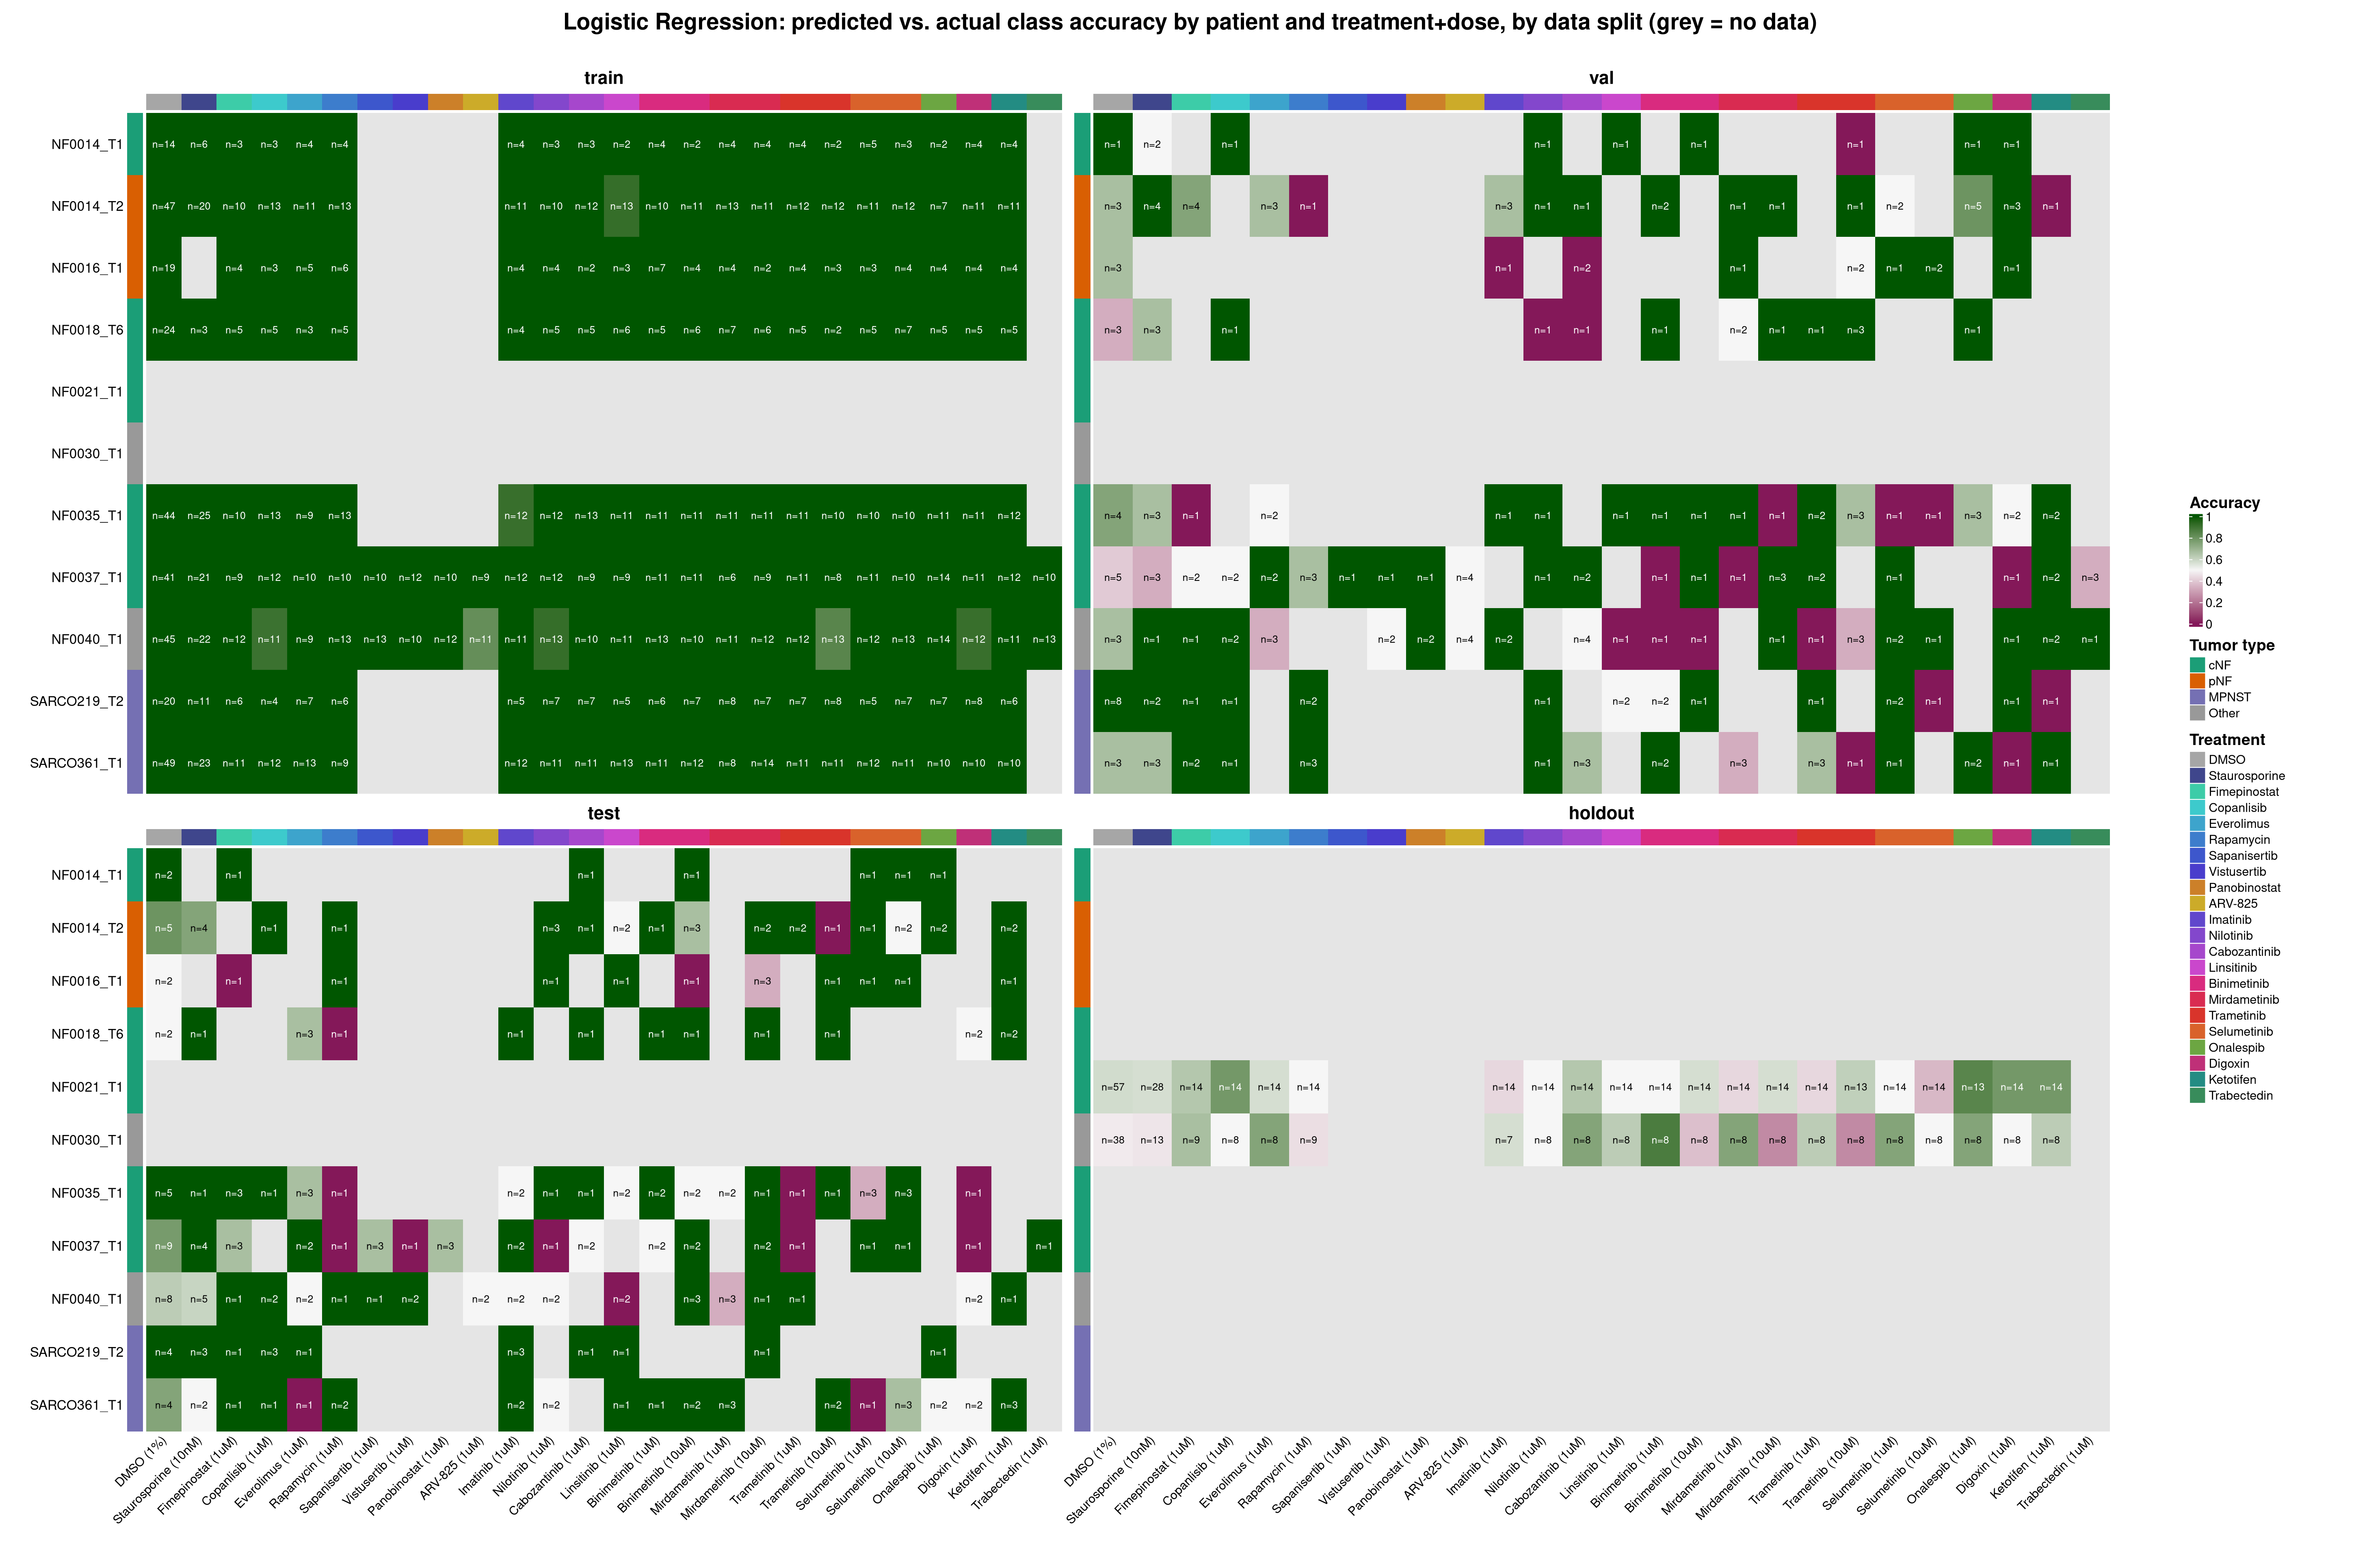

In [3]:
suppressPackageStartupMessages(library(IRdisplay))
display_png(file = heatmap_png_path)

## Second heatmap: predicted vs. actual class, irrespective of patient/treatment

The heatmap above is deliberately broken out by patient and treatment+dose. This second heatmap answers a narrower question -- within each data split, how well does predicted class line up with actual class overall? -- so it collapses across patient and treatment entirely: a 2x2 split grid (same `[train | val] / [test | holdout]` layout) of actual-class x predicted-class matrices, with cell color = row-normalized proportion (recall) on the **same accuracy color palette** as the first heatmap, so the two figures read consistently together. Reads the `confusion_summary.csv` written by `2a.retrieve_morphology_class_info.ipynb` and renders with native R code directly in the next cell (no subprocess, unlike the first heatmap) -- it draws straight to an explicitly-opened `png()` device and closes it before the cell finishes, so there's nothing left on IRkernel's own notebook device for it to auto-capture/replay, which is what the first heatmap's subprocess indirection exists to avoid.

In [4]:
confusion_csv_path <- normalizePath("../results/confusion_summary.csv")
confusion_heatmap_png_path <- file.path(
  "..", "figures",
  sprintf("confusion_heatmap_%s.png", gsub(" ", "_", MODEL_NAME))
)
dir.create(dirname(confusion_heatmap_png_path), showWarnings = FALSE, recursive = TRUE)
confusion_heatmap_png_path <- normalizePath(confusion_heatmap_png_path, mustWork = FALSE)

# Render the predicted-vs-actual confusion-matrix heatmap with ComplexHeatmap,
# natively in this cell (see the markdown above for why this is safe here but
# NOT for the first heatmap). Unlike that first heatmap (rows = patient,
# columns = treatment+dose, faceted by split), this one collapses across
# patient and treatment entirely: rows = actual class, columns = predicted
# class, cell color = proportion of that (split, actual class) group
# predicted as that column (row-normalized recall, [0, 1] scale) -- the same
# accuracy-style color palette as the first heatmap, so the diagonal cells
# here are directly comparable in meaning and color to that heatmap's
# "accuracy" cells. Still faceted into the same 2x2 split grid
# (train | val / test | holdout), for the same reason as the first heatmap:
# split is not 1:1 with actual class, so it can't collapse into a single
# panel.
confusion_df <- read.csv(confusion_csv_path, stringsAsFactors = FALSE)
confusion_df <- confusion_df[confusion_df$model == MODEL_NAME, ]

classes <- sort(unique(c(confusion_df$actual, confusion_df$predicted)))

# same [0, 1] red-green scale as the first heatmap's accuracy cells, so the
# two figures read consistently side by side
proportion_fun <- colorRamp2(
  c(0, 0.5, 1),
  hcl.colors(3, palette = "Red-Green")
)

quadrant_splits <- c("train", "val", "test", "holdout")
missing_confusion_splits <- setdiff(quadrant_splits, unique(confusion_df$split))
if (length(missing_confusion_splits) > 0) {
  cat("No data for split(s): ", paste(missing_confusion_splits, collapse = ", "), " (panel will be empty)\n")
}

# choose white or black cell text by the fill color's own luminance, same
# rule as the first heatmap
confusion_text_color_for_fill <- function(fill) {
  rgb_vals <- col2rgb(fill) / 255
  luminance <- 0.299 * rgb_vals[1, ] + 0.587 * rgb_vals[2, ] + 0.114 * rgb_vals[3, ]
  ifelse(luminance > 0.55, "black", "white")
}

build_confusion_cell_fun <- function(n_mat) {
  force(n_mat)
  function(j, i, x, y, width, height, fill) {
    n_val <- n_mat[i, j]
    if (!is.na(n_val)) {
      grid.text(
        sprintf("n=%d", n_val), x, y,
        gp = gpar(fontsize = 9, col = confusion_text_color_for_fill(fill))
      )
    }
  }
}

# every panel carries no legend of its own -- the single shared legend is
# built once below and drawn in its own grid.layout cell, same pattern as
# the first heatmap
build_confusion_panel <- function(split_name, show_row_names, show_col_names) {
  sub <- confusion_df[confusion_df$split == split_name, ]

  proportion_mat <- matrix(
    NA_real_,
    nrow = length(classes), ncol = length(classes),
    dimnames = list(classes, classes)
  )
  n_mat <- matrix(
    NA_integer_,
    nrow = length(classes), ncol = length(classes),
    dimnames = list(classes, classes)
  )
  for (k in seq_len(nrow(sub))) {
    proportion_mat[sub$actual[k], sub$predicted[k]] <- sub$proportion[k]
    n_mat[sub$actual[k], sub$predicted[k]] <- sub$n[k]
  }

  Heatmap(
    proportion_mat,
    name = paste0("Proportion_", split_name), # unique per panel for clarity
    # when debugging; each panel is drawn into its own viewport
    # independently, so a duplicate name across panels is not an issue here.
    col = proportion_fun,
    na_col = "grey90",
    cluster_rows = FALSE,
    cluster_columns = FALSE,
    row_order = classes,
    column_order = classes,
    row_title = "Actual",
    row_title_gp = gpar(fontsize = 12, fontface = "bold"),
    row_names_side = "left",
    row_names_gp = gpar(fontsize = 11),
    column_names_rot = 45,
    column_names_gp = gpar(fontsize = 11),
    column_title = split_name,
    column_title_gp = gpar(fontsize = 16, fontface = "bold"),
    show_row_names = show_row_names,
    show_column_names = show_col_names,
    show_heatmap_legend = FALSE,
    cell_fun = build_confusion_cell_fun(n_mat)
  )
}

# [ train | val     ]
# [ test  | holdout ]
# row names on the left column of the grid; column names on the bottom row
confusion_ht_train <- build_confusion_panel("train", show_row_names = TRUE, show_col_names = FALSE)
confusion_ht_val <- build_confusion_panel("val", show_row_names = FALSE, show_col_names = FALSE)
confusion_ht_test <- build_confusion_panel("test", show_row_names = TRUE, show_col_names = TRUE)
confusion_ht_holdout <- build_confusion_panel("holdout", show_row_names = FALSE, show_col_names = TRUE)

lgd_proportion <- Legend(
  col_fun = proportion_fun, title = "Proportion\n(recall)",
  title_gp = gpar(fontsize = 14, fontface = "bold"), labels_gp = gpar(fontsize = 11),
  grid_height = unit(5, "mm"), legend_height = unit(3.5, "cm")
)

n_classes <- length(classes)
confusion_panel_height_in <- 0.6 * n_classes + 2.3
confusion_panel_width_in <- 0.6 * n_classes + 2.3
confusion_height_in <- 2 * confusion_panel_height_in # no overall title, so no extra margin needed
confusion_width_in <- 2 * confusion_panel_width_in + 2.2 # +2.2 for the legend column

# Draw straight to an explicitly-opened png() device, then close it before
# this cell finishes -- see the markdown above for why that keeps IRkernel's
# own auto-capture/replay mechanism out of the way (unlike the first
# heatmap, which has to shell out to Rscript for the same reason).
png(confusion_heatmap_png_path, width = confusion_width_in, height = confusion_height_in, units = "in", res = 200)
grid.newpage()
pushViewport(viewport(
  layout = grid.layout(
    nrow = 2, ncol = 3,
    widths = unit.c(unit(confusion_panel_width_in, "in"), unit(confusion_panel_width_in, "in"), unit(2.2, "in")),
    heights = unit(c(confusion_panel_height_in, confusion_panel_height_in), "in")
  )
))

confusion_panel_positions <- list(
  list(ht = confusion_ht_train, row = 1, col = 1),
  list(ht = confusion_ht_val, row = 1, col = 2),
  list(ht = confusion_ht_test, row = 2, col = 1),
  list(ht = confusion_ht_holdout, row = 2, col = 2)
)
for (p in confusion_panel_positions) {
  pushViewport(viewport(layout.pos.row = p$row, layout.pos.col = p$col))
  draw(p$ht, newpage = FALSE)
  popViewport()
}

pushViewport(viewport(layout.pos.row = 1:2, layout.pos.col = 3))
draw(lgd_proportion, x = unit(0.5, "npc"), y = unit(0.5, "npc"))
popViewport()

popViewport()
invisible(dev.off())

cat(sprintf(
  "wrote %s (%d x %d confusion matrix, 2x2 split grid)\n",
  confusion_heatmap_png_path, n_classes, n_classes
))

wrote ../figures/confusion_heatmap_Logistic_Regression.png (5 x 5 confusion matrix, 2x2 split grid)


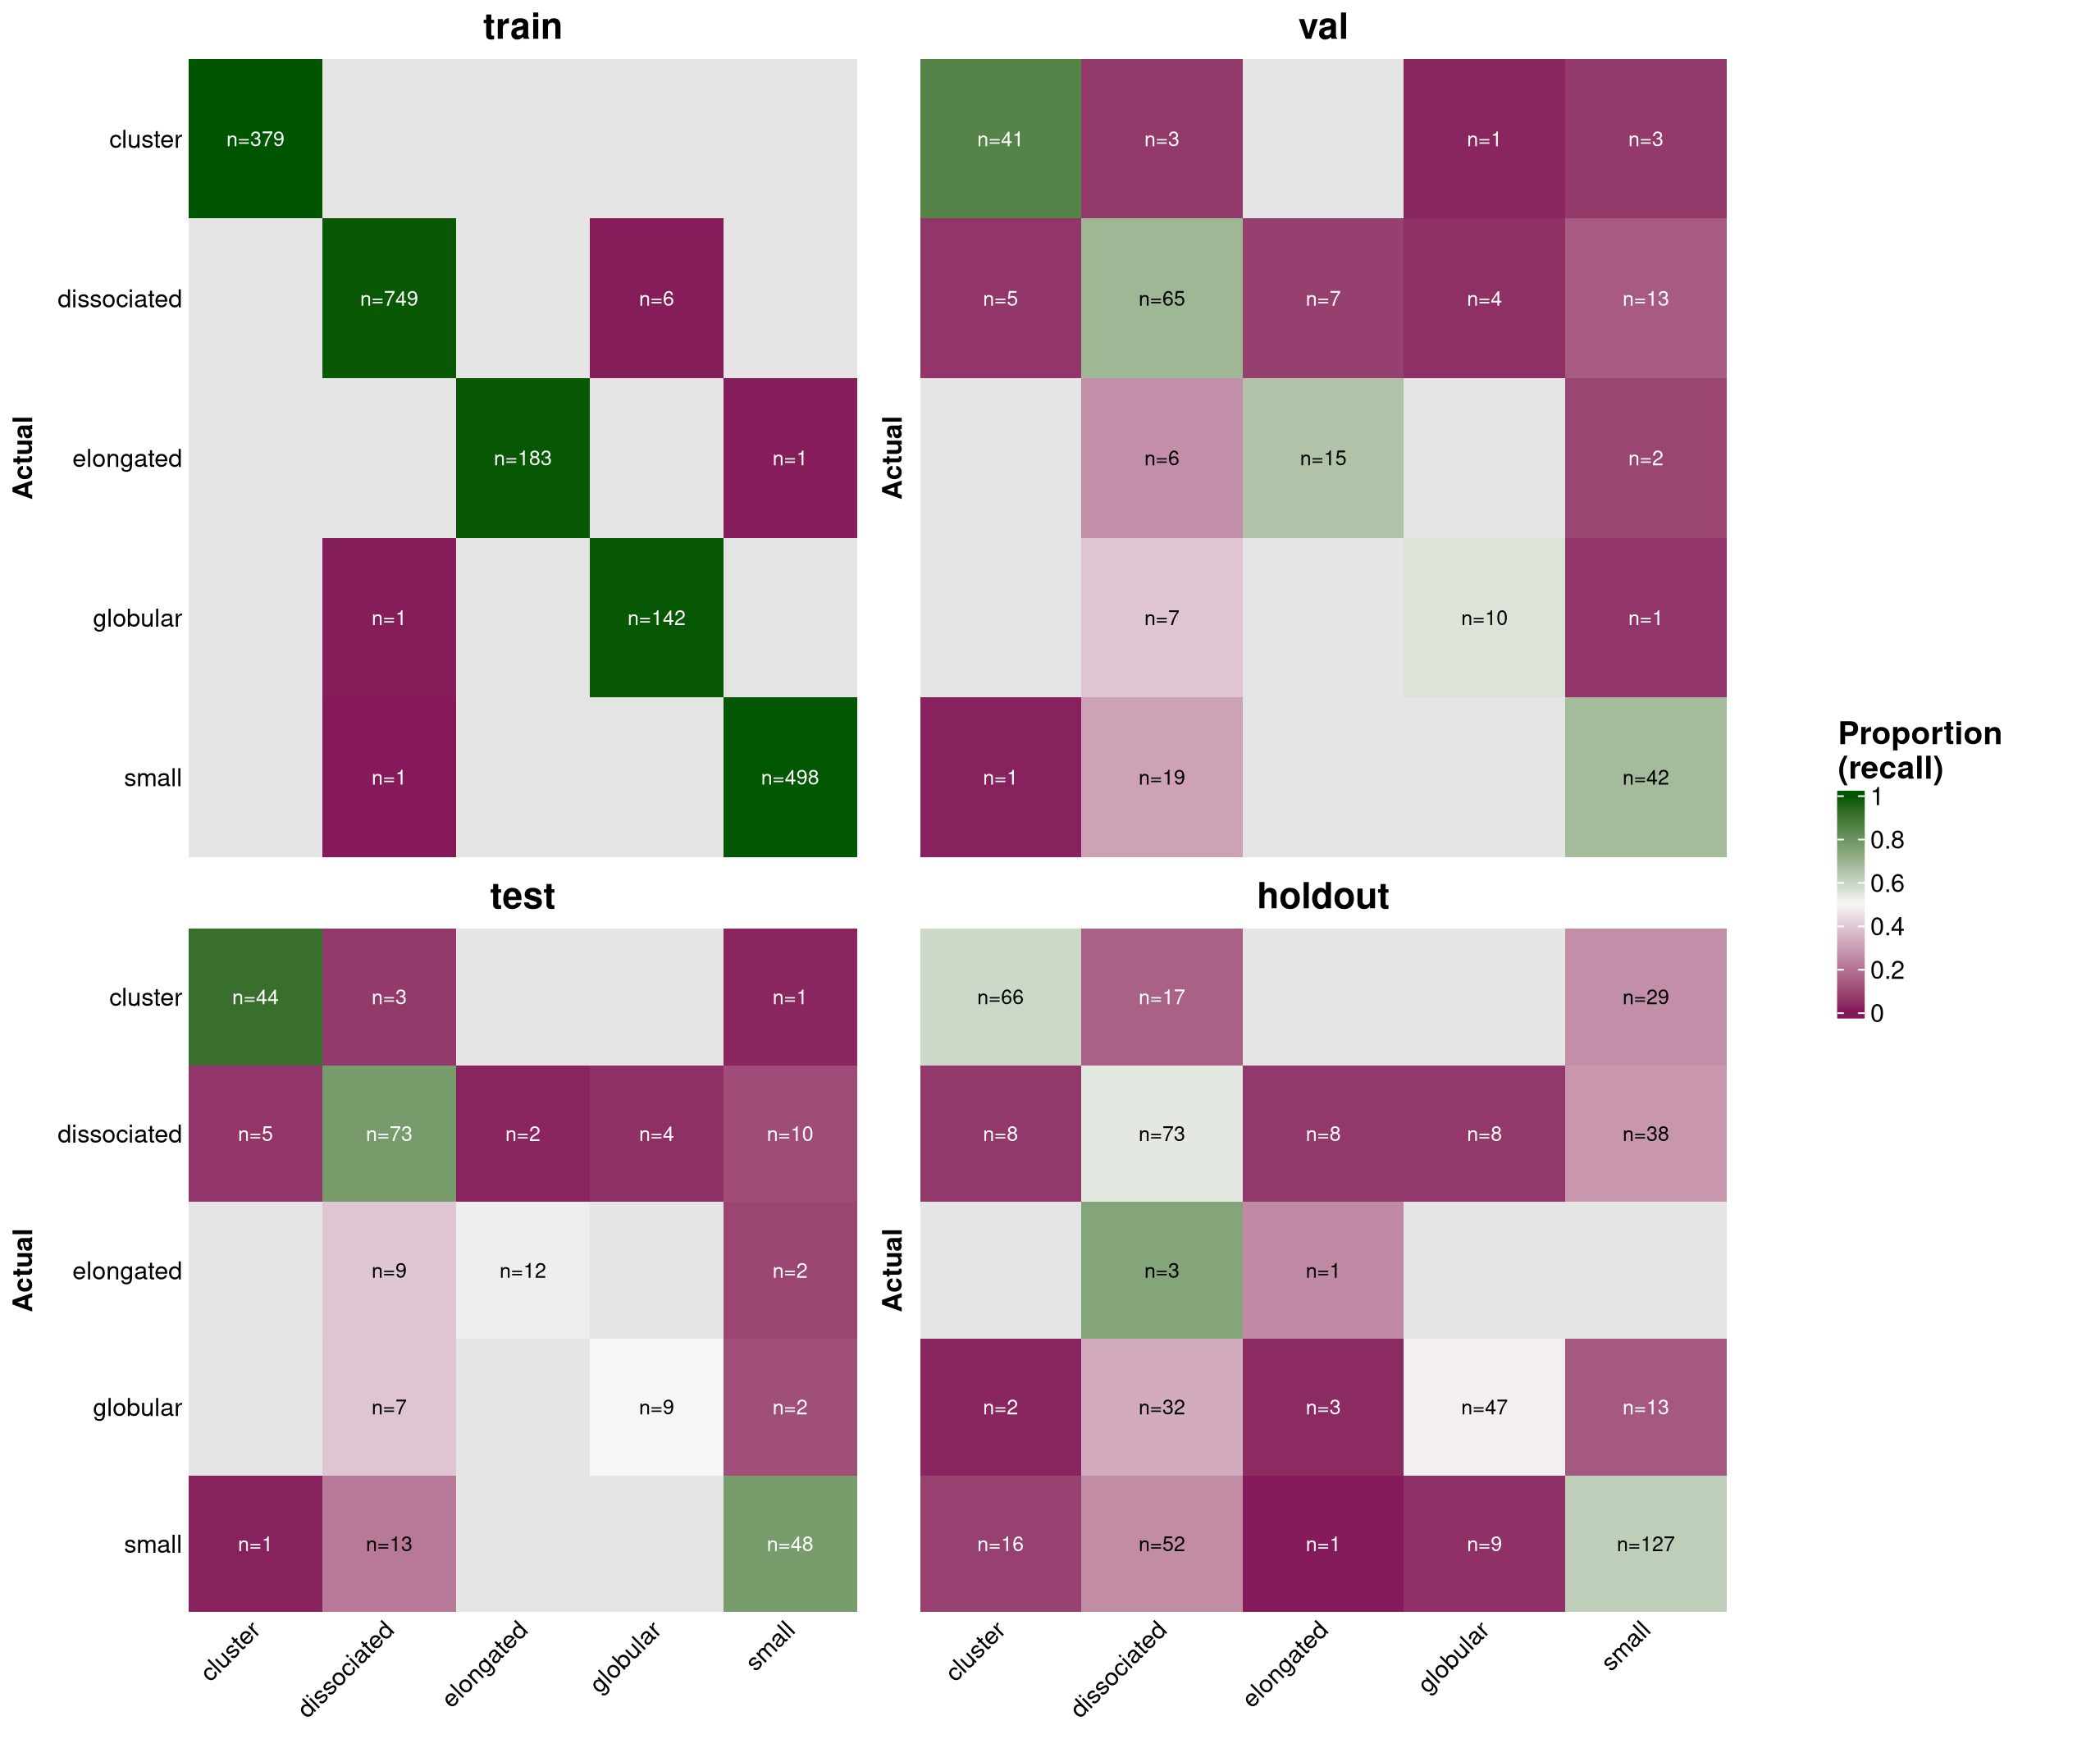

In [5]:
display_png(file = confusion_heatmap_png_path)